# Étude de cas : prédire la souscription à un dépôt à terme bancaire (UCI 222)

**Cours BD & DS · ENCG Settat · S7 FIN et CI** · Exemple de projet complet (corrigé type)
**Algorithme principal :** 14, gradient boosting (classification) · **Données :** UCI Bank Marketing, licence CC BY 4.0

Ce notebook reproduit toute l'étude de cas, dans l'ordre du rapport : introduction, état de l'art, travaux liés, données, exploration, préparation, algorithme, protocole, résultats, discussion, conclusion, références et annexes. Il télécharge lui-même les données : il suffit de lancer **Exécution > Tout exécuter** (2 à 3 minutes).

> **À propos des chiffres commentés.** Les interprétations reprennent les chiffres de l'exécution de référence (Python 3.13, scikit-learn 1.9.1). Selon la version installée dans Colab, les résultats recalculés peuvent varier légèrement ; les cellules de code affichent toujours les valeurs de votre exécution.

**Sommaire**
0. Configuration
1. Introduction
2. État de l'art
3. Travaux liés
4. Jeu de données
5. Exploration
6. Préparation
7. Algorithme
8. Protocole expérimental
9. Résultats
10. Discussion des résultats
11. Conclusion
12. Références et citations
13. Annexes

## 0. Configuration

In [1]:
# Facultatif : pour retrouver exactement les chiffres de l'exécution de référence,
# décommentez la ligne suivante, exécutez-la, puis relancez tout le notebook.
# !pip -q install scikit-learn==1.9.1

import platform, json, zipfile, shutil, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance

GRAINE = 42
BASE = Path('projet_uci222')
DONNEES = BASE / 'data' / 'raw'
FIGURES = BASE / 'figures'
for dossier in (DONNEES, FIGURES):
    dossier.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 9})
virgule = FuncFormatter(lambda v, pos: '{:g}'.format(v).replace('.', ','))
def fr(x, d=1):
    """Nombre au format français (virgule décimale)."""
    return '{:.{d}f}'.format(x, d=d).replace('.', ',')

R = {}  # tous les résultats chiffrés, enregistrés à la fin
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 1. Introduction

**Contexte.** Entre 2008 et 2010, une banque portugaise a appelé ses clients pour leur proposer un dépôt à terme. Seuls 11,7 % ont accepté. Classer les clients *avant* l'appel permettrait au responsable de campagne de concentrer ses appels sur les clients les plus susceptibles de souscrire.

**Problématique.** Avec les seules informations disponibles avant un appel, peut-on classer les clients selon leur probabilité de souscrire mieux qu'une règle simple ?

**Objectif mesurable.** Sur la période de test (les 20 % d'appels les plus récents), obtenir une aire sous la courbe précision-rappel (AP) supérieure d'au moins 10 % (en relatif) à celle de la meilleure référence naïve.

**Nature du problème.** Classification binaire déséquilibrée : la cible vaut « oui » pour 11,7 % des clients. L'AP est alors plus informative que l'AUC ROC [6].

## 2. État de l'art

Prédire la réponse à une campagne de marketing direct est un problème de *scoring* : on attribue un score à chaque client, puis on appelle les mieux classés. La régression logistique est la référence statistique de ce type de score [4]. Le gradient boosting d'arbres capte des relations non linéaires et des interactions sans les spécifier [5]. Sur des classes déséquilibrées, la courbe précision-rappel décrit mieux la qualité d'un classement que la courbe ROC [6]. Enfin, quand la population ou le contexte évoluent, les performances mesurées sur le passé se dégradent : c'est la dérive conceptuelle [7].

| Approche | Principe | Atouts | Limites | Réf. |
| --- | --- | --- | --- | --- |
| Règle métier | Appeler les clients ayant déjà souscrit lors d'une campagne passée | Simple, explicable | Ignore les clients sans historique | Cette étude |
| Régression logistique | Combinaison linéaire des variables, transformée en probabilité | Interprétable, robuste | Effets linéaires sur la log-cote | [4] |
| Gradient boosting d'arbres | Somme d'arbres ajoutés un à un pour corriger les erreurs | Non-linéarités, interactions | Moins interprétable, réglages | [5] |
| Réseaux de neurones, SVM | Frontières de décision non linéaires | Très flexibles | Réglages et calcul exigeants | [2], [3] |

## 3. Travaux liés

| Travail | Données | Méthode | Résultat principal | Différence avec cette étude |
| --- | --- | --- | --- | --- |
| Moro *et al.*, 2011 [2] | 45 211 contacts de 2008 à 2010, 29 variables dont la durée d'appel | Bayes naïf, arbre de décision, SVM ; tirage aléatoire 2/3 et 1/3, répété 20 fois | SVM : AUC 0,938 ; la durée d'appel est la variable la plus influente | Durée d'appel exclue (connue après l'appel) ; découpage chronologique |
| Moro *et al.*, 2014 [3] | Contacts de 2008 à 2013, 150 variables réduites à 22, dont des indicateurs socio-économiques | Régression logistique, arbre, réseau de neurones, SVM ; fenêtre glissante | Réseau de neurones : AUC 0,8 ; 79 % des souscripteurs atteints en appelant la moitié des clients | 16 variables publiques seulement ; algorithme du support (gradient boosting) |

**Positionnement.** Comme Moro *et al.* (2014), nous évaluons le modèle sur une période postérieure à l'apprentissage. Contrairement à Moro *et al.* (2011), nous excluons la durée d'appel. Avec moins de variables et un protocole plus strict, nos scores ne sont pas directement comparables aux leurs.

## 4. Jeu de données

### 4.1 Téléchargement depuis l'UCI Machine Learning Repository

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
fichier = DONNEES / 'bank-full.csv'
if not fichier.exists():
    try:
        archive = DONNEES / 'bank_marketing.zip'
        urllib.request.urlretrieve(URL, archive)
        with zipfile.ZipFile(archive) as z:
            z.extract('bank.zip', DONNEES)
        with zipfile.ZipFile(DONNEES / 'bank.zip') as z:
            for nom in ('bank-full.csv', 'bank-names.txt'):
                z.extract(nom, DONNEES)
        (DONNEES / 'bank.zip').unlink(); archive.unlink()
        print('Données téléchargées depuis', URL)
    except Exception as erreur:
        print('Téléchargement impossible :', erreur)
        print('Téléversez bank-full.csv dans', DONNEES, '(menu Fichiers à gauche), puis relancez cette cellule.')
else:
    print('Données déjà présentes :', fichier)

Données téléchargées depuis https://archive.ics.uci.edu/static/public/222/bank+marketing.zip


In [3]:
df = pd.read_csv(DONNEES / 'bank-full.csv', sep=';')
print('Dimensions :', df.shape)
df.head()

Dimensions : (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.dtypes.to_frame('type').T

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
type,int64,object,object,object,object,int64,object,object,object,int64,object,int64,int64,int64,int64,object,object


### 4.2 Description

- **Nom et source :** « Bank Marketing », UCI Machine Learning Repository, jeu n° 222 [1], fichier `bank-full.csv`, https://archive.ics.uci.edu/dataset/222/bank+marketing
- **Date d'extraction :** 24/11/2026 · **Licence :** CC BY 4.0
- **Taille :** 45 211 observations, 16 variables explicatives et la cible, de mai 2008 à novembre 2010 ; lignes triées par date, sans l'année
- **Unité d'observation :** un client contacté lors d'une campagne de télémarketing
- **Variable cible :** `y`, souscription d'un dépôt à terme (« yes » ou « no »)
- **Adéquation :** le jeu décrit le client et ses contacts passés, connus avant l'appel, et son ordre chronologique permet une évaluation réaliste
- **Limites :** une seule banque, en pleine crise financière ; année absente ; modalité « unknown » fréquente ; taux de souscription très instable dans le temps ; durée d'appel inutilisable

**Variable exclue : `duration`.** La durée de l'appel n'est connue qu'après l'appel, quand la réponse est déjà connue ; la documentation du jeu demande de l'écarter pour un modèle prédictif réaliste.

### 4.3 Dictionnaire des principales variables

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| `y` | Souscription du dépôt à terme | binaire | | cible | 0 |
| `duration` | Durée du dernier appel | numérique | secondes | exclue (fuite) | 0 |
| `poutcome` | Résultat de la campagne précédente | catégorielle | | explicative | 81,7 (« unknown ») |
| `contact` | Canal du dernier contact | catégorielle | | explicative | 28,8 (« unknown ») |
| `month` | Mois du dernier contact | catégorielle | | explicative | 0 |
| `balance` | Solde annuel moyen | numérique | euros | explicative | 0 |
| `campaign` | Nombre d'appels pendant la campagne | numérique | appels | explicative | 0 |
| `deja_contacte` | 1 si `pdays` ≠ -1 : client déjà contacté auparavant | binaire | | créée | 0 |

Les 9 autres variables (âge, métier, situation familiale, éducation, défaut, prêt immobilier, prêt personnel, jour, `pdays`, `previous`) sont utilisées telles quelles.

## 5. Exploration

### 5.1 Qualité des données

In [5]:
df['cible'] = (df['y'] == 'yes').astype(int)
df['rang'] = np.arange(len(df))          # les lignes sont triées par date (mai 2008 à nov. 2010)
R['n'] = int(len(df))
R['doublons'] = int(df.drop(columns=['rang', 'cible']).duplicated().sum())
R['nan'] = int(df.isna().sum().sum())
inconnus = (df == 'unknown').sum()
R['inconnus_pct'] = (inconnus[inconnus > 0] / len(df) * 100).round(1).to_dict()
R['taux_global'] = float(df['cible'].mean())
R['balance_negatif_pct'] = float((df['balance'] < 0).mean() * 100)
R['campaign_max'] = int(df['campaign'].max())
print('Doublons :', R['doublons'], '| valeurs NaN :', R['nan'])
print('Modalité « unknown » (% des lignes) :', R['inconnus_pct'])
print('Taux de souscription global :', fr(R['taux_global'] * 100), '%')
print('Soldes négatifs :', fr(R['balance_negatif_pct']), '% | campaign max :', R['campaign_max'])
df[['age', 'balance', 'campaign', 'pdays', 'previous', 'duration']].describe().T.round(1)

Doublons : 0 | valeurs NaN : 0
Modalité « unknown » (% des lignes) : {'job': 0.6, 'education': 4.1, 'contact': 28.8, 'poutcome': 81.7}
Taux de souscription global : 11,7 %
Soldes négatifs : 8,3 % | campaign max : 63


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.9,10.6,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,102127.0
campaign,45211.0,2.8,3.1,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.6,2.3,0.0,0.0,0.0,0.0,275.0
duration,45211.0,258.2,257.5,0.0,103.0,180.0,319.0,4918.0


**Lecture.** Aucun doublon ni valeur NaN, mais la modalité « unknown » remplace les absences : 81,7 % pour `poutcome` (clients jamais contactés auparavant), 28,8 % pour `contact`, 4,1 % pour `education`, 0,6 % pour `job`. Elle est gardée comme modalité à part entière, car elle porte une information. Les soldes négatifs (8,3 %) et les 63 appels maximum de `campaign` sont plausibles (découvert, client très relancé) : ils sont conservés.

### 5.2 Graphiques

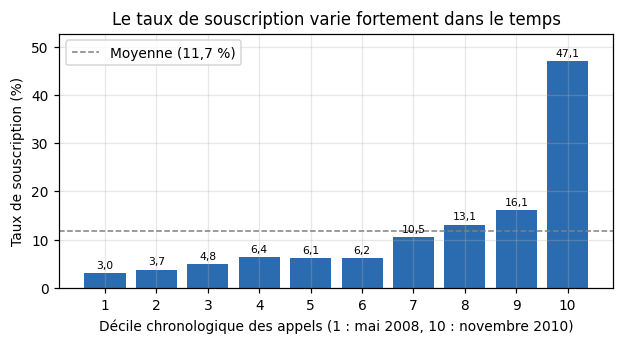

In [6]:
# Figure 1 : taux de souscription par décile chronologique
deciles = pd.qcut(df['rang'], 10, labels=False)
taux_dec = df.groupby(deciles)['cible'].mean()
R['taux_deciles'] = [round(float(v) * 100, 1) for v in taux_dec]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(range(1, 11), taux_dec * 100, color='#2b6cb0')
ax.axhline(R['taux_global'] * 100, ls='--', color='grey', lw=1, label='Moyenne ({} %)'.format(fr(R['taux_global'] * 100)))
for i, v in enumerate(taux_dec * 100, start=1):
    ax.text(i, v + 1, fr(v), ha='center', fontsize=7)
ax.set_ylim(0, taux_dec.max() * 100 * 1.12)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Décile chronologique des appels (1 : mai 2008, 10 : novembre 2010)')
ax.set_ylabel('Taux de souscription (%)')
ax.set_title('Le taux de souscription varie fortement dans le temps')
ax.legend(loc='upper left')
fig.savefig(FIGURES / 'fig1_derive_temporelle.png', dpi=200, bbox_inches='tight')
plt.show()

**Lecture de la figure 1.** Le taux passe de 3,0 % dans le premier décile (mai 2008) à 47,1 % dans le dernier (fin 2010). Le jeu n'est pas stationnaire : un découpage aléatoire mélangerait des périodes très différentes. Le découpage sera donc chronologique.

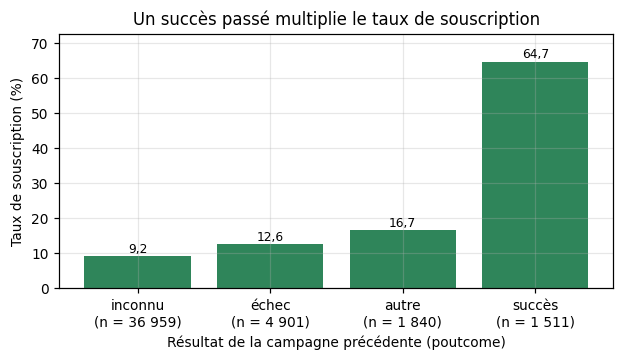

In [7]:
# Figure 2 : taux de souscription selon le résultat de la campagne précédente
ordre = ['unknown', 'failure', 'other', 'success']
noms = {'unknown': 'inconnu', 'failure': 'échec', 'other': 'autre', 'success': 'succès'}
t = df.groupby('poutcome')['cible'].agg(['mean', 'size']).loc[ordre]
R['poutcome'] = {k: {'taux': round(float(t.loc[k, 'mean']) * 100, 1), 'n': int(t.loc[k, 'size'])} for k in ordre}
fig, ax = plt.subplots(figsize=(6.5, 3))
etiquettes = ['{}\n(n = {})'.format(noms[k], '{:,}'.format(t.loc[k, 'size']).replace(',', ' ')) for k in ordre]
ax.bar(etiquettes, t['mean'] * 100, color='#2f855a')
for i, v in enumerate(t['mean'] * 100):
    ax.text(i, v + 1, fr(v), ha='center', fontsize=8)
ax.set_ylim(0, t['mean'].max() * 100 * 1.12)
ax.set_xlabel('Résultat de la campagne précédente (poutcome)')
ax.set_ylabel('Taux de souscription (%)')
ax.set_title('Un succès passé multiplie le taux de souscription')
fig.savefig(FIGURES / 'fig2_campagne_precedente.png', dpi=200, bbox_inches='tight')
plt.show()

**Lecture de la figure 2.** Les clients dont la campagne précédente avait réussi souscrivent à 64,7 %, contre 9,2 % pour ceux sans historique. C'est le signal le plus fort, d'où la référence naïve « succès précédent » ; il ne concerne toutefois que 1 511 clients.

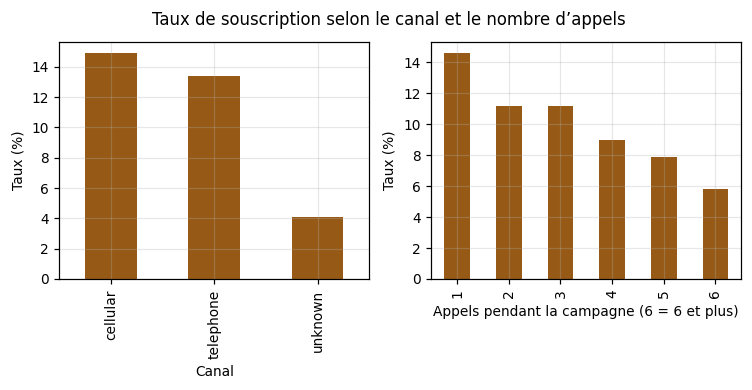

In [8]:
# Figure complémentaire : taux selon le canal et le nombre d'appels
canal = df.groupby('contact')['cible'].mean().mul(100).round(1)
appels = df.assign(appels=df['campaign'].clip(upper=6)).groupby('appels')['cible'].mean().mul(100).round(1)
R['canal'], R['appels'] = canal.to_dict(), {int(k): float(v) for k, v in appels.items()}
fig, axes = plt.subplots(1, 2, figsize=(8, 2.8))
canal.plot.bar(ax=axes[0], color='#975a16'); axes[0].set_xlabel('Canal'); axes[0].set_ylabel('Taux (%)')
appels.plot.bar(ax=axes[1], color='#975a16'); axes[1].set_xlabel('Appels pendant la campagne (6 = 6 et plus)'); axes[1].set_ylabel('Taux (%)')
fig.suptitle('Taux de souscription selon le canal et le nombre d’appels')
fig.savefig(FIGURES / 'figA_canal_appels.png', dpi=200, bbox_inches='tight')
plt.show()

**Lecture.** Quand le canal n'est pas renseigné, le taux tombe à 4,1 %, contre 14,9 % sur mobile. Le taux baisse aussi avec l'insistance : 14,6 % au premier appel, 5,8 % au-delà de cinq. Relancer davantage ne paie pas.

## 6. Préparation

In [9]:
# duration est exclue : elle n'est connue qu'après l'appel (fuite de données)
df['deja_contacte'] = (df['pdays'] != -1).astype(int)   # variable créée
CAT = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
NUM = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'deja_contacte']
X, y = df[CAT + NUM], df['cible']

# Découpage chronologique : 80 % les plus anciens pour l'apprentissage, 20 % les plus récents pour le test
n_test = int(round(0.2 * len(df)))
X_app, X_test = X.iloc[:-n_test], X.iloc[-n_test:]
y_app, y_test = y.iloc[:-n_test], y.iloc[-n_test:]
R['n_app'], R['n_test'] = len(X_app), len(X_test)
R['taux_app'], R['taux_test'] = float(y_app.mean()), float(y_test.mean())
print('Apprentissage : {} lignes, taux {} % | Test : {} lignes, taux {} %'.format(
    R['n_app'], fr(R['taux_app'] * 100), R['n_test'], fr(R['taux_test'] * 100)))
# Vérification de l'ordre : dernières lignes d'apprentissage, premières lignes de test
pd.concat([df.loc[X_app.index[-2:], ['rang', 'month', 'day', 'y']], df.loc[X_test.index[:2], ['rang', 'month', 'day', 'y']]])

Apprentissage : 36169 lignes, taux 6,7 % | Test : 9042 lignes, taux 31,6 %


,rang,month,day,y
36167,36167,may,11,no
36168,36168,may,11,no
36169,36169,may,11,no
36170,36170,may,11,no


In [10]:
# Pipelines : les transformations sont ajustées sur l'apprentissage seulement, dans chaque pli
tscv = TimeSeriesSplit(n_splits=4)
plis = list(tscv.split(X_app))
prep_arbre = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), CAT),
    ('num', 'passthrough', NUM)])
gb = Pipeline([('prep', prep_arbre),
               ('modele', HistGradientBoostingClassifier(max_iter=200, categorical_features=list(range(len(CAT))),
                                                         random_state=GRAINE))])
prep_lin = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('num', StandardScaler(), NUM)])
lr = Pipeline([('prep', prep_lin), ('modele', LogisticRegression(max_iter=3000))])
print('Plis de validation (apprentissage, validation) :', [(len(a), len(v)) for a, v in plis])

Plis de validation (apprentissage, validation) : [(7237, 7233), (14470, 7233), (21703, 7233), (28936, 7233)]


**Choix de préparation.**

1. **Nettoyage :** aucune ligne supprimée ; « unknown » conservée comme modalité ; valeurs extrêmes conservées.
2. **Variable créée :** `deja_contacte` ; `duration` retirée.
3. **Encodage :** ordinal pour les 9 variables catégorielles, traitées nativement par le gradient boosting ; pas de mise à l'échelle, inutile pour des arbres. Pour la régression logistique : encodage *one-hot* et standardisation.
4. **Découpage chronologique :** les 36 169 premiers appels pour l'apprentissage (taux 6,7 %), les 9 042 derniers pour le test (taux 31,6 %). L'affichage confirme que le test commence au rang 36 169, juste après l'apprentissage.

**Prévention des fuites.**

- ✔ Transformations ajustées sur l'apprentissage seulement, dans un `Pipeline`.
- ✔ Découpage chronologique, sans mélange.
- ✔ Variables construites avec le passé seulement ; la cible porte sur l'appel lui-même, sans horizon.
- ✔ Aucune variable ne contient la cible : `duration` est exclue.
- ✔ Jeu de test utilisé une seule fois, à la fin.

## 7. Algorithme

**Choix.** Algorithme 14 du support : gradient boosting en classification (`HistGradientBoostingClassifier` [8]). Il capte les effets non linéaires (âge, solde) et les interactions sans les spécifier, et traite nativement les variables catégorielles. La régression logistique (algorithme 8), plus simple, sert de comparaison.

**Principe.** Le modèle additionne $M$ arbres peu profonds. Partant d'un score constant, chaque nouvel arbre est ajusté au gradient négatif de la perte logistique, c'est-à-dire aux erreurs du modèle courant, puis ajouté avec un poids $\eta$ [5]. Le score final est transformé en probabilité par la fonction logistique :

$$\hat{p}(x) = \frac{1}{1 + e^{-F_M(x)}}, \qquad F_M(x) = F_0 + \eta \sum_{m=1}^{M} h_m(x)$$

où $x$ est le vecteur des variables d'un client, $h_m$ le $m$-ième arbre (au plus $L$ feuilles), $\eta$ le taux d'apprentissage, $M$ le nombre d'arbres (200), $F_0$ le score initial (log-cote du taux de souscription) et $\hat{p}(x)$ la probabilité estimée de souscrire.

**Paramètres appris :** la structure de chaque arbre (variables, seuils de coupure, regroupements de modalités) et la valeur de chaque feuille.

| Hyperparamètre | Rôle et effet attendu | Valeurs testées |
| --- | --- | --- |
| `learning_rate` ($\eta$) | Poids de chaque arbre : plus petit, apprentissage plus lent et plus stable | 0,03 ; 0,1 ; 0,3 |
| `max_leaf_nodes` ($L$) | Complexité de chaque arbre : plus de feuilles, plus d'interactions et plus de risque de surapprentissage | 7 ; 15 ; 31 |

## 8. Protocole expérimental

| Ensemble | Période ou proportion | Observations |
| --- | --- | --- |
| Apprentissage | 80 % les plus anciens (rangs 0 à 36 168), taux 6,7 % | 36 169 |
| Validation | `TimeSeriesSplit`, 4 plis dans l'apprentissage | 4 × 7 233 |
| Test | 20 % les plus récents (rangs 36 169 à 45 210), taux 31,6 % | 9 042 |

- **Références naïves :** classe majoritaire (score constant) et règle « succès précédent » (score 1 si `poutcome` vaut « success »).
- **Validation :** 9 configurations essayées pour le gradient boosting ; régression logistique sans réglage.
- **Métrique principale :** AP, aire sous la courbe précision-rappel, comprise entre le taux de souscription (hasard) et 1.
- **Métriques secondaires :** AUC ROC ; rappel à 20 %, part des souscripteurs retrouvés en appelant les 20 % de clients les mieux classés.
- **Graine aléatoire :** 42.

In [11]:
# Références naïves évaluées sur les plis de validation
def score_regle(Xp):
    return (Xp['poutcome'] == 'success').astype(int).to_numpy()

def ap_plis(fonction_score):
    return np.array([average_precision_score(y_app.iloc[v], fonction_score(X_app.iloc[v])) for a, v in plis])

ap_maj, ap_regle = ap_plis(lambda Xp: np.zeros(len(Xp))), ap_plis(score_regle)
R['val'] = {'majoritaire': [float(ap_maj.mean()), float(ap_maj.std())], 'regle': [float(ap_regle.mean()), float(ap_regle.std())]}
print('AP validation, classe majoritaire :', fr(ap_maj.mean(), 3), '±', fr(ap_maj.std(), 3))
print('AP validation, règle « succès précédent » :', fr(ap_regle.mean(), 3), '±', fr(ap_regle.std(), 3))

AP validation, classe majoritaire : 0,076 ± 0,035
AP validation, règle « succès précédent » : 0,082 ± 0,044


In [12]:
# Recherche sur grille : 3 x 3 = 9 configurations, métrique AP, validation chronologique
grille = {'modele__learning_rate': [0.03, 0.1, 0.3], 'modele__max_leaf_nodes': [7, 15, 31]}
recherche = GridSearchCV(gb, grille, scoring='average_precision', cv=tscv, n_jobs=-1, return_train_score=True)
recherche.fit(X_app, y_app)
res = pd.DataFrame(recherche.cv_results_)
tab = res[['param_modele__learning_rate', 'param_modele__max_leaf_nodes', 'mean_test_score', 'std_test_score', 'mean_train_score']]
tab = tab.rename(columns={'param_modele__learning_rate': 'learning_rate', 'param_modele__max_leaf_nodes': 'max_leaf_nodes',
                          'mean_test_score': 'AP_validation', 'std_test_score': 'ecart_type', 'mean_train_score': 'AP_apprentissage'}).round(3)
R['grille'] = tab.to_dict(orient='records')
R['meilleur'] = {k.replace('modele__', ''): v for k, v in recherche.best_params_.items()}
i = recherche.best_index_
R['val']['gb'] = [float(res.loc[i, 'mean_test_score']), float(res.loc[i, 'std_test_score'])]
params = {'modele__' + k: v for k, v in R['meilleur'].items()}
print('Meilleure configuration :', R['meilleur'])
tab.sort_values('AP_validation', ascending=False)

Meilleure configuration : {'learning_rate': 0.3, 'max_leaf_nodes': 7}


,learning_rate,max_leaf_nodes,AP_validation,ecart_type,AP_apprentissage
6,0.30,7,0.100,0.061,0.335
0,0.03,7,0.088,0.044,0.172
2,0.03,31,0.088,0.043,0.403
8,0.30,31,0.088,0.049,0.479
3,0.10,7,0.087,0.045,0.262
5,0.10,31,0.087,0.041,0.452
1,0.03,15,0.085,0.040,0.280
4,0.10,15,0.085,0.042,0.410
7,0.30,15,0.083,0.043,0.398


In [13]:
# Modèle de comparaison : régression logistique (sans réglage)
ap_lr = []
for a, v in plis:
    lr.fit(X_app.iloc[a], y_app.iloc[a])
    ap_lr.append(average_precision_score(y_app.iloc[v], lr.predict_proba(X_app.iloc[v])[:, 1]))
R['val']['lr'] = [float(np.mean(ap_lr)), float(np.std(ap_lr))]
print('AP validation, régression logistique :', fr(np.mean(ap_lr), 3), '±', fr(np.std(ap_lr), 3))

AP validation, régression logistique : 0,094 ± 0,051


In [14]:
# Diagnostic des plis de validation (gradient boosting retenu)
diag = []
for k, (a, v) in enumerate(plis, start=1):
    m = clone(gb).set_params(**params).fit(X_app.iloc[a], y_app.iloc[a])
    s_v = m.predict_proba(X_app.iloc[v])[:, 1]
    diag.append({'pli': k, 'taux_validation_%': round(float(y_app.iloc[v].mean() * 100), 1),
                 'AP_gb': round(float(average_precision_score(y_app.iloc[v], s_v)), 3),
                 'AP_regle': round(float(average_precision_score(y_app.iloc[v], score_regle(X_app.iloc[v]))), 3),
                 'clients_avec_historique_%': round(float((X_app.iloc[v]['poutcome'] != 'unknown').mean() * 100), 1),
                 'mois_jamais_vus': len(set(X_app.iloc[v]['month']) - set(X_app.iloc[a]['month']))})
R['diag'] = diag
pd.DataFrame(diag)

,pli,taux_validation_%,AP_gb,AP_regle,clients_avec_historique_%,mois_jamais_vus
0,1,4.9,0.050,0.049,0.0,2
1,2,6.6,0.081,0.066,0.0,1
2,3,5.5,0.064,0.055,17.9,5
3,4,13.7,0.204,0.158,34.9,2


**Lecture de la validation.** Les 9 configurations sont indiscernables (AP de 0,083 à 0,088 pour un écart-type de 0,04) ; la meilleure en moyenne (0,03 et 7 feuilles) est aussi la plus simple, elle est retenue. Les configurations à 31 feuilles atteignent une AP d'apprentissage de 0,41 à 0,45 sans gain en validation : signe de surapprentissage.

**Diagnostic des plis.** Dans les deux premiers plis, aucun client n'a d'historique de campagne, et 1 à 5 mois de validation n'ont jamais été vus à l'apprentissage. Le signal y est presque nul pour tous les modèles. Seul le dernier pli, le plus proche du test, laisse voir un gain (AP 0,163 contre 0,158 pour la règle).

## 9. Résultats

Le jeu de test est utilisé **une seule fois**, ci-dessous.

In [ ]:
meilleur_gb = recherche.best_estimator_            # réajusté sur tout l'apprentissage
lr.fit(X_app, y_app)
scores = {'majoritaire': np.zeros(len(X_test)), 'regle': score_regle(X_test),
          'lr': lr.predict_proba(X_test)[:, 1], 'gb': meilleur_gb.predict_proba(X_test)[:, 1]}

def rappel_top(y_vrai, s, part=0.2):
    k = int(round(part * len(s)))
    ordre_s = np.argsort(-s, kind='stable')[:k]
    return float(y_vrai.to_numpy()[ordre_s].sum() / y_vrai.sum())

def auc_plis(fabrique_score):
    vals = [roc_auc_score(y_app.iloc[v], fabrique_score(a, v)) for a, v in plis]
    return [float(np.mean(vals)), float(np.std(vals))]

def score_gb_pli(a, v):
    return clone(gb).set_params(**params).fit(X_app.iloc[a], y_app.iloc[a]).predict_proba(X_app.iloc[v])[:, 1]
def score_lr_pli(a, v):
    return clone(lr).fit(X_app.iloc[a], y_app.iloc[a]).predict_proba(X_app.iloc[v])[:, 1]

R['val_auc'] = {'majoritaire': auc_plis(lambda a, v: np.zeros(len(v))),
                'regle': auc_plis(lambda a, v: score_regle(X_app.iloc[v])),
                'lr': auc_plis(score_lr_pli), 'gb': auc_plis(score_gb_pli)}
R['test'] = {nom: {'AP': float(average_precision_score(y_test, s)), 'AUC': float(roc_auc_score(y_test, s)),
                   'rappel20': rappel_top(y_test, s) if nom in ('lr', 'gb') else None} for nom, s in scores.items()}

libelles = {'majoritaire': 'Référence : classe majoritaire', 'regle': 'Référence : règle « succès précédent »',
            'lr': 'Régression logistique (comparaison)', 'gb': 'Gradient boosting (retenu)'}
synthese = pd.DataFrame({
    'AP validation': ['{} ± {}'.format(fr(R['val'][k][0], 3), fr(R['val'][k][1], 3)) for k in libelles],
    'AP test': [fr(R['test'][k]['AP'], 3) for k in libelles],
    'AUC validation': ['{} ± {}'.format(fr(R['val_auc'][k][0], 3), fr(R['val_auc'][k][1], 3)) for k in libelles],
    'AUC test': [fr(R['test'][k]['AUC'], 3) for k in libelles],
    'Rappel à 20 %': ['' if R['test'][k]['rappel20'] is None else fr(R['test'][k]['rappel20'] * 100) + ' %' for k in libelles]},
    index=libelles.values())
synthese

In [ ]:
# Figure 3 : courbes précision-rappel sur le test
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for nom, lib, coul in [('gb', 'Gradient boosting (AP = {})', '#2b6cb0'), ('lr', 'Régression logistique (AP = {})', '#975a16')]:
    p, r, _ = precision_recall_curve(y_test, scores[nom])
    ax.plot(r, p, color=coul, lw=1.5, label=lib.format(fr(R['test'][nom]['AP'], 3)))
# La règle n'a que deux niveaux de score : un seul point de fonctionnement, pas de courbe interpolée
sel = scores['regle'] == 1
r_regle, p_regle = float(y_test[sel].sum() / y_test.sum()), float(y_test[sel].mean())
ax.plot([r_regle], [p_regle], 'o', color='#2f855a', ms=7,
        label='Règle « succès précédent » (AP = {})'.format(fr(R['test']['regle']['AP'], 3)))
ax.axhline(R['taux_test'], color='grey', ls=':', label='Classe majoritaire (AP = {})'.format(fr(R['test']['majoritaire']['AP'], 3)))
ax.xaxis.set_major_formatter(virgule); ax.yaxis.set_major_formatter(virgule)
ax.set_ylim(0, 1.02)
ax.set_xlabel('Rappel (part des souscripteurs retrouvés)'); ax.set_ylabel('Précision')
ax.set_title('Courbes précision-rappel sur la période de test')
ax.legend(fontsize=7, loc='upper right')
fig.savefig(FIGURES / 'fig3_courbes_precision_rappel.png', dpi=200, bbox_inches='tight')
plt.show()

R['point_regle'] = {'rappel': r_regle, 'precision': p_regle, 'n_appels': int(sel.sum())}
for nom in ('gb', 'lr'):
    p, r, _ = precision_recall_curve(y_test, scores[nom])
    R['point_regle']['precision_' + nom] = float(p[r >= r_regle][-1])
print('Règle : {} appels, rappel {} %, précision {} %'.format(R['point_regle']['n_appels'], fr(r_regle * 100), fr(p_regle * 100)))
print('Au même rappel : gradient boosting {} %, régression logistique {} %'.format(
    fr(R['point_regle']['precision_gb'] * 100), fr(R['point_regle']['precision_lr'] * 100)))

**Lecture des résultats.** Sur le test, le gradient boosting atteint une AP de 0,485, contre 0,436 pour la règle et 0,316 pour la classe majoritaire. La régression logistique fait jeu égal (0,489) ; le gradient boosting classe un peu mieux selon l'AUC (0,706 contre 0,684).

La figure 3 nuance ce gain : en appelant ses 1 301 clients (rappel 31,7 %), la règle atteint une précision de 69,5 %, contre 52,9 % pour le gradient boosting et 57,4 % pour la régression logistique au même rappel. En validation, l'AP du hasard vaut 0,076 et aucun modèle ne s'en écarte nettement.

In [ ]:
# Analyse des erreurs : politique « appeler les 20 % de clients les mieux classés »
s = scores['gb']
k = int(round(0.2 * len(s)))
appele = np.zeros(len(s), dtype=int); appele[np.argsort(-s, kind='stable')[:k]] = 1
yt = y_test.to_numpy()
R['confusion'] = {'VP': int(((appele == 1) & (yt == 1)).sum()), 'FP': int(((appele == 1) & (yt == 0)).sum()),
                  'FN': int(((appele == 0) & (yt == 1)).sum()), 'VN': int(((appele == 0) & (yt == 0)).sum())}
test = df.loc[X_test.index].assign(score=s, appele=appele)
rappel_groupe = test[test['cible'] == 1].groupby('poutcome')['appele'].agg(['mean', 'size'])
moitie = len(test) // 2
R['moities'] = [float(average_precision_score(test['cible'].iloc[:moitie], test['score'].iloc[:moitie])),
                float(average_precision_score(test['cible'].iloc[moitie:], test['score'].iloc[moitie:]))]
R['proba_moyenne_test'] = float(s.mean())
R['AUC_app_gb'] = float(roc_auc_score(y_app, meilleur_gb.predict_proba(X_app)[:, 1]))
print('Matrice de confusion (appeler les', k, 'mieux classés) :', R['confusion'])
print('Précision :', fr(R['confusion']['VP'] / k * 100), '% | rappel :', fr(R['test']['gb']['rappel20'] * 100), '%')
print('Rappel des souscripteurs selon poutcome (%) :', (rappel_groupe['mean'] * 100).round(1).to_dict())
print('AP première et seconde moitié du test :', fr(R['moities'][0], 3), 'et', fr(R['moities'][1], 3))
print('Probabilité moyenne prédite :', fr(R['proba_moyenne_test'], 3), '| taux réel :', fr(R['taux_test'], 3))
print('AUC apprentissage :', fr(R['AUC_app_gb'], 3), '| AUC test :', fr(R['test']['gb']['AUC'], 3))

**Analyse des erreurs.** En appelant les 20 % de clients les mieux classés (1 808 appels), on obtient 970 souscriptions (précision 53,7 %, contre 31,6 % en moyenne) et l'on manque 1 886 souscripteurs (rappel 34,0 %). Le modèle retrouve 66,9 % des souscripteurs ayant un succès passé, mais moins de 20 % des autres : il dépend fortement de `poutcome`. Il se trompe davantage au début du test : AP de 0,322 sur la première moitié (taux 16,1 %), contre 0,529 sur la seconde (taux 47,1 %).

In [ ]:
# Importance des variables par permutation (sur le test, métrique AP)
imp = permutation_importance(meilleur_gb, X_test, y_test, scoring='average_precision', n_repeats=5,
                             random_state=GRAINE, n_jobs=-1)
importance = pd.DataFrame({'variable': X_test.columns, 'baisse_AP': imp.importances_mean, 'ecart_type': imp.importances_std})
importance = importance.sort_values('baisse_AP', ascending=False).round(4)
R['importance'] = importance.head(5).to_dict(orient='records')
importance.head(8)

In [ ]:
# Illustration : 5 clients de la période de test, non vus à l'apprentissage
choix = [test['score'].idxmax(),
         test[(test['cible'] == 1) & (test['poutcome'] == 'success')]['score'].idxmin(),
         test[test['cible'] == 1]['score'].idxmin(),
         test[test['cible'] == 0]['score'].idxmax(),
         test['score'].sub(test['score'].median()).abs().idxmin()]
illustration = test.loc[choix, ['rang', 'month', 'age', 'job', 'contact', 'poutcome', 'campaign', 'score', 'y']].round({'score': 3})
illustration

**Importance des variables.** Le modèle s'appuie surtout sur `poutcome` et `month` : leur permutation fait baisser l'AP de 0,086 et 0,058, contre moins de 0,01 pour les autres variables. Ce sont des associations, pas des causes.

**Exemples.** Le premier client (retraité, succès passé) obtient 0,894 et souscrit. Le quatrième, retraité de 70 ans sans historique, obtient 0,867 mais refuse : faux positif. Le deuxième a un succès passé mais, appelé en juillet, n'obtient que 0,097 et souscrit : l'effet du mois appris sur le passé ne se transpose pas toujours.

In [ ]:
# Contrôle, NON RETENU pour l'évaluation : validation croisée aléatoire stratifiée sur tout le jeu
cv_alea = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
ctl = cross_validate(clone(gb).set_params(**params), X, y, cv=cv_alea, scoring=['roc_auc', 'average_precision'], n_jobs=-1)
R['controle_aleatoire'] = {'AUC': float(ctl['test_roc_auc'].mean()), 'AP': float(ctl['test_average_precision'].mean())}
print('Découpage aléatoire (contrôle) : AUC', fr(R['controle_aleatoire']['AUC'], 3), '| AP', fr(R['controle_aleatoire']['AP'], 3))

## 10. Discussion des résultats

**Réponse à l'objectif.** L'objectif est atteint, de peu : l'AP du gradient boosting dépasse de 11,3 % celle de la meilleure référence (0,485 contre 0,436), pour un seuil de 10 %.

**Interprétation.** Le gain d'AP vient du classement des clients sans historique ; en tête de liste, la règle « succès précédent » reste plus précise.

**Surapprentissage et généralisation.** L'AUC passe de 0,740 sur l'apprentissage à 0,706 sur le test : la configuration retenue, la plus simple, surapprend peu. Le vrai problème est la dérive [7] : les premiers plis de validation n'ont aucun historique de campagne et contiennent des mois jamais vus, et la probabilité moyenne prédite sur le test (0,135) est très inférieure au taux observé (0,316). Le contrôle par découpage aléatoire donne une AUC de 0,795, plus flatteuse car elle mélange les périodes.

**Comparaison avec les travaux liés.** Nos scores sont inférieurs à ceux de Moro *et al.* (AUC 0,938 puis 0,8). L'écart s'explique par l'exclusion de la durée d'appel, absente au moment de décider, par l'évaluation chronologique et par l'absence des indicateurs socio-économiques utilisés en 2014.

**Limites et biais.** Une seule banque, sur une période de crise ; année absente ; une seule période de test, en fin 2010 ; le modèle dépend d'un historique absent pour 82 % des clients.

**Pistes d'amélioration.** (1) Appeler d'abord les clients au succès passé, puis classer les autres avec le modèle, en l'évaluant sur une nouvelle période. (2) Réentraîner sur une fenêtre glissante, avec les indicateurs économiques du jeu `bank-additional`, et recalibrer les probabilités.

## 11. Conclusion

Avec les seules informations disponibles avant l'appel, le gradient boosting classe mieux les clients que la règle « succès précédent » (AP 0,485 contre 0,436) : l'objectif est atteint, de peu. Il ne fait pas mieux qu'une régression logistique, et pour les premiers appels la règle simple reste plus précise. L'enseignement principal est méthodologique : la forte dérive du taux de souscription impose une évaluation chronologique, plus sévère qu'un découpage aléatoire mais seule représentative d'un usage réel.

## 12. Références et citations

1. « Bank Marketing », UCI Machine Learning Repository, jeu n° 222, créé par P. Cortez et S. Moro, déposé le 13/02/2012, licence CC BY 4.0, https://archive.ics.uci.edu/dataset/222/bank+marketing, consulté le 24/11/2026.
2. S. Moro, R. Laureano, P. Cortez, « Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology », *Proceedings of the European Simulation and Modelling Conference (ESM'2011)*, Guimarães, Portugal, p. 117-121, 2011.
3. S. Moro, P. Cortez, P. Rita, « A data-driven approach to predict the success of bank telemarketing », *Decision Support Systems*, vol. 62, p. 22-31, 2014, doi:10.1016/j.dss.2014.03.001.
4. D. W. Hosmer, S. Lemeshow, R. X. Sturdivant, *Applied Logistic Regression*, 3e éd., Wiley, 2013.
5. J. H. Friedman, « Greedy function approximation: A gradient boosting machine », *The Annals of Statistics*, vol. 29, n° 5, p. 1189-1232, 2001.
6. T. Saito, M. Rehmsmeier, « The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets », *PLOS ONE*, vol. 10, n° 3, e0118432, 2015.
7. J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy, A. Bouchachia, « A survey on concept drift adaptation », *ACM Computing Surveys*, vol. 46, n° 4, article 44, 2014.
8. F. Pedregosa *et al.*, « Scikit-learn: Machine Learning in Python », *Journal of Machine Learning Research*, vol. 12, p. 2825-2830, 2011.
9. Support du cours BD & DS, notebook `Tp_ML.ipynb`, ENCG Settat, 2026.

## 13. Annexes

### A. Reproduction

Ce notebook télécharge les données, refait toute l'analyse et enregistre ses résultats. La cellule suivante rassemble les figures, les résultats chiffrés et les données dans `projet_uci222.zip` et propose son téléchargement (dans Colab).

### B. Déclaration des outils d'IA

| Outil ou ressource | Date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Claude (Anthropic) | 24/11/2026 | Exemple produit à la demande de l'enseignant(e) : code, analyse et rédaction | Tout le notebook | Chiffres repris des sorties de l'exécution de référence ; références vérifiées en ligne |

In [ ]:
# Enregistrement des résultats et archive téléchargeable
def propre(o):
    if isinstance(o, dict): return {str(k): propre(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [propre(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
with open(BASE / 'resultats.json', 'w', encoding='utf-8') as f:
    json.dump(propre(R), f, ensure_ascii=False, indent=1)
archive = shutil.make_archive('projet_uci222', 'zip', BASE)
print('Archive créée :', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Hors de Colab : récupérez le fichier', archive, 'dans le dossier courant.')